In [6]:
%pip install pytz

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import pandas as pd
!pip install scikit-learn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pytz


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
df = pd.read_csv(r"C:\Users\Ezhilarasi\OneDrive\Desktop\AI_ML_Project\ML\Shopper Spectrum\online_retail.csv")
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [9]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2022-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2022-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2022-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2022-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2022-12-01 08:26:00,3.39,17850.0,United Kingdom


In [10]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [11]:
(df.isnull().sum()/ len(df))*100

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64

In [12]:
def treat_outliers_iqr(df,variable):
    q1=df[variable].quantile(0.25)
    q3=df[variable].quantile(0.75)
    iqr=q1-q3
    ll=q1-1.5*iqr
    up=q3-1.5*iqr
    df=df[(df[variable]>=ll)&(df[variable]<=up)]
    return df
def remove_outlier(df):
    for col in df.select_dtypes(include='number').columns:
        df= treat_outliers_iqr(df,col)
        return df

In [13]:
for i in df.select_dtypes(include='O').columns:
    if df[i].isnull().sum()>0:
        print(i)
        df[i].fillna(df[i].mode()[0],inplace=True)

C:\Users\Ezhilarasi\AppData\Local\Temp\ipykernel_8188\3096230428.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for i in df.select_dtypes(include='O').columns:
C:\Users\Ezhilarasi\AppData\Local\Temp\ipykernel_8188\3096230428.py:4: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doin

Description


In [14]:
# Step 2: Data Preprocessing

# 1. Remove rows with missing CustomerID
df = df.dropna(subset=['CustomerID'])

# 2. Exclude cancelled invoices (InvoiceNo starting with 'C')
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# 3. Remove negative or zero quantities and prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Reset index after cleaning
df = df.reset_index(drop=True)

df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2022-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2022-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2022-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2022-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2022-12-01 08:26:00,3.39,17850.0,United Kingdom


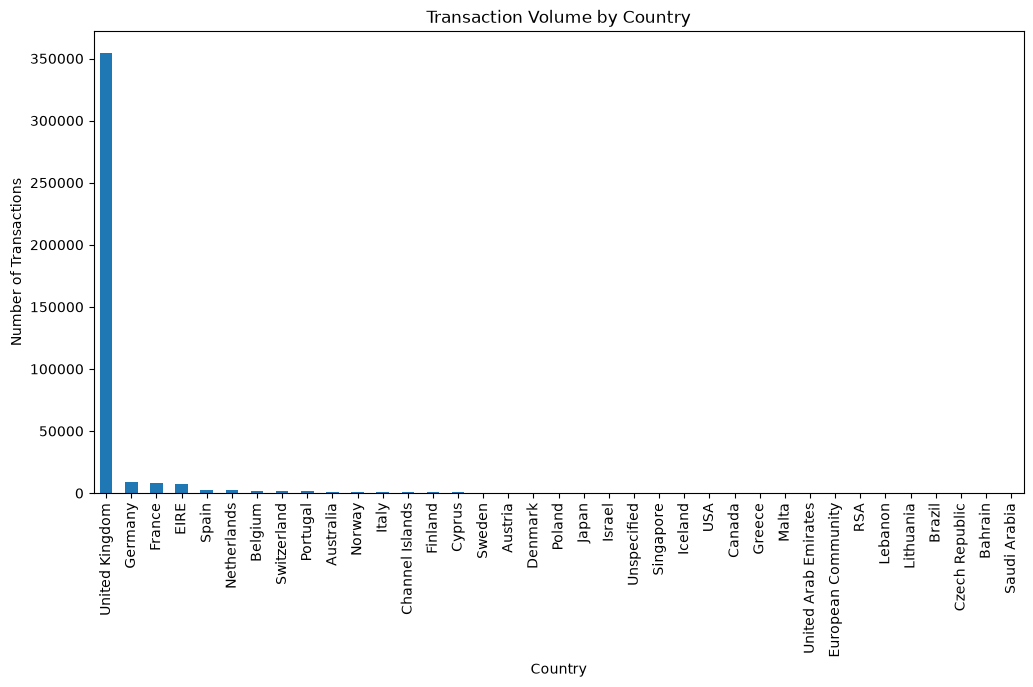

In [15]:
#Transaction Volume by Country
plt.figure(figsize=(12,6))
df['Country'].value_counts().sort_values(ascending=False).plot(kind='bar')
plt.title("Transaction Volume by Country")
plt.xlabel("Country")
plt.ylabel("Number of Transactions")
plt.show()


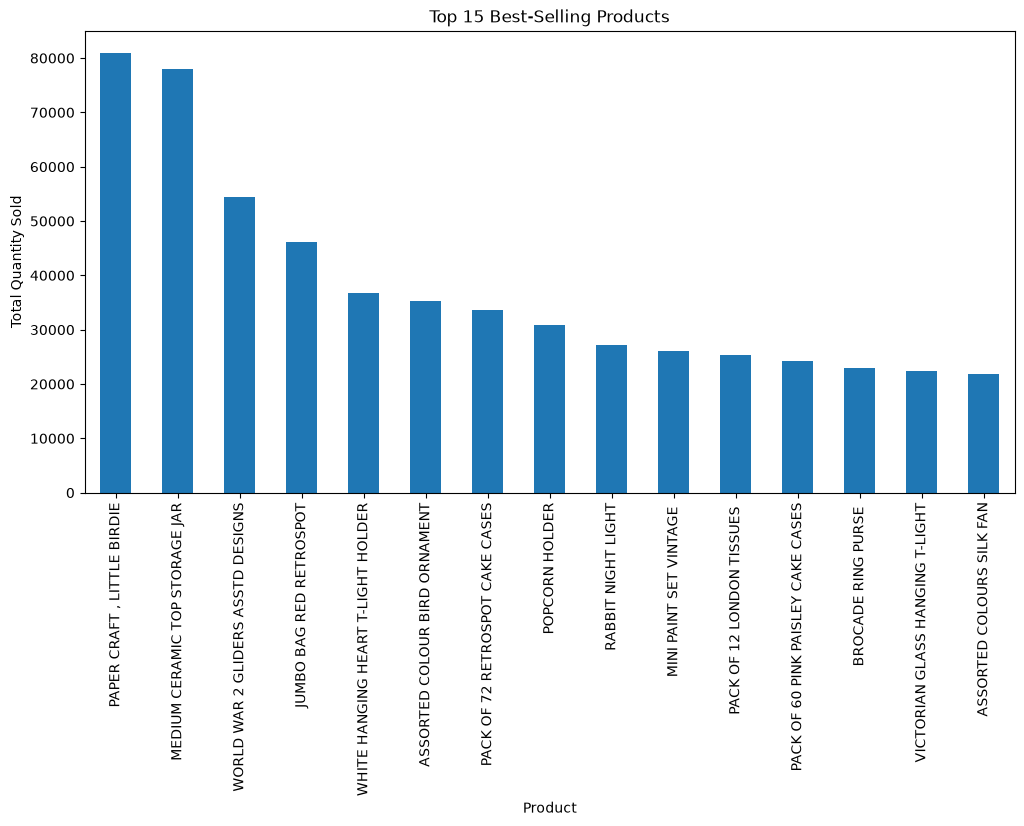

In [16]:
#Top-Selling Products
top_products = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(15)

plt.figure(figsize=(12,6))
top_products.plot(kind='bar')
plt.title("Top 15 Best-Selling Products")
plt.xlabel("Product")
plt.ylabel("Total Quantity Sold")
plt.show()


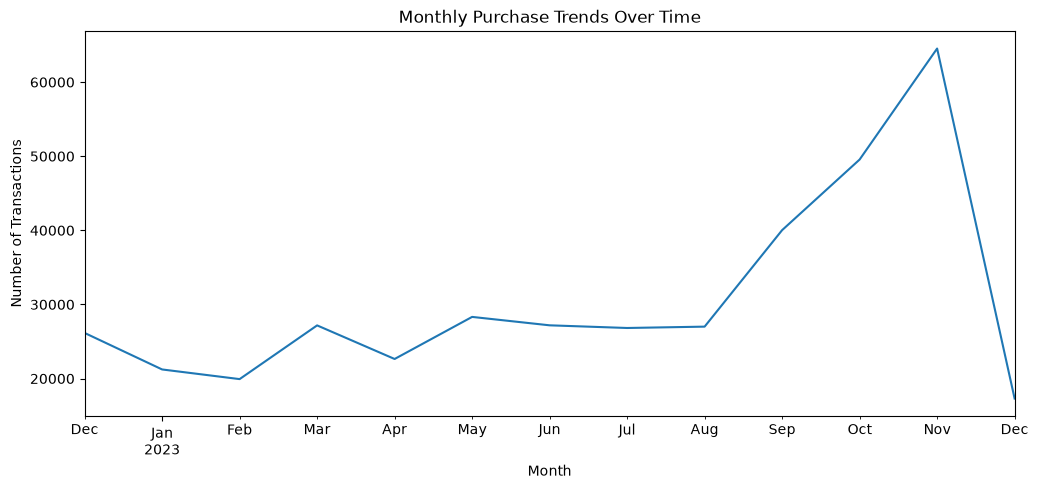

In [17]:
#Purchase Trends Over Time
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')

#Monthly Trend
monthly_sales = df.groupby('InvoiceMonth')['InvoiceNo'].count()

plt.figure(figsize=(12,5))
monthly_sales.plot()
plt.title("Monthly Purchase Trends Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.show()


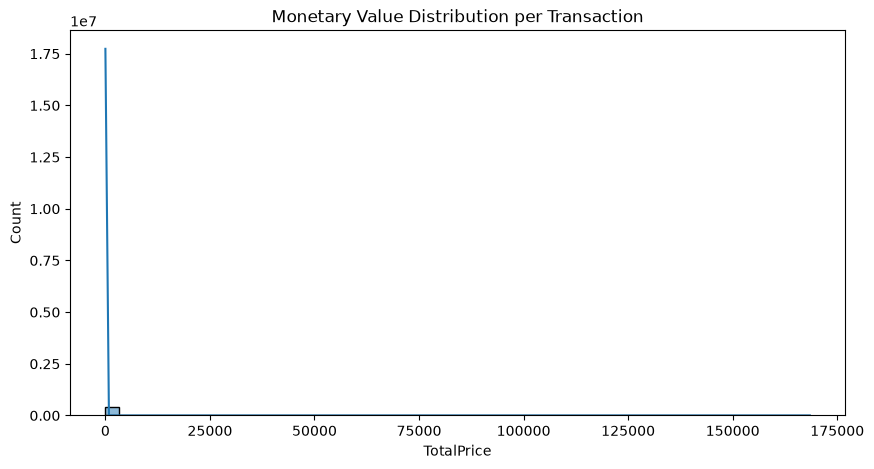

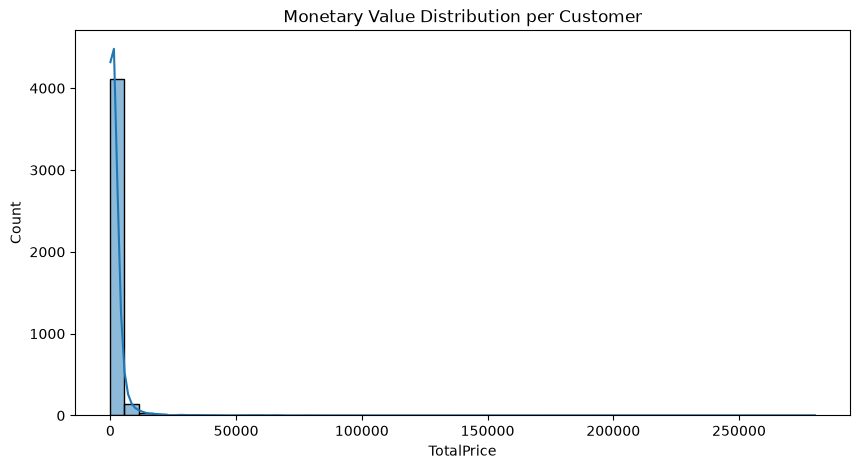

In [18]:
#4️ Monetary Distribution per Transaction & Customer
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

# Per Transaction
plt.figure(figsize=(10,5))
sns.histplot(df['TotalPrice'], bins=50, kde=True)
plt.title("Monetary Value Distribution per Transaction")
plt.show()

# Per Customer
customer_value = df.groupby('CustomerID')['TotalPrice'].sum()

plt.figure(figsize=(10,5))
sns.histplot(customer_value, bins=50, kde=True)
plt.title("Monetary Value Distribution per Customer")
plt.show()



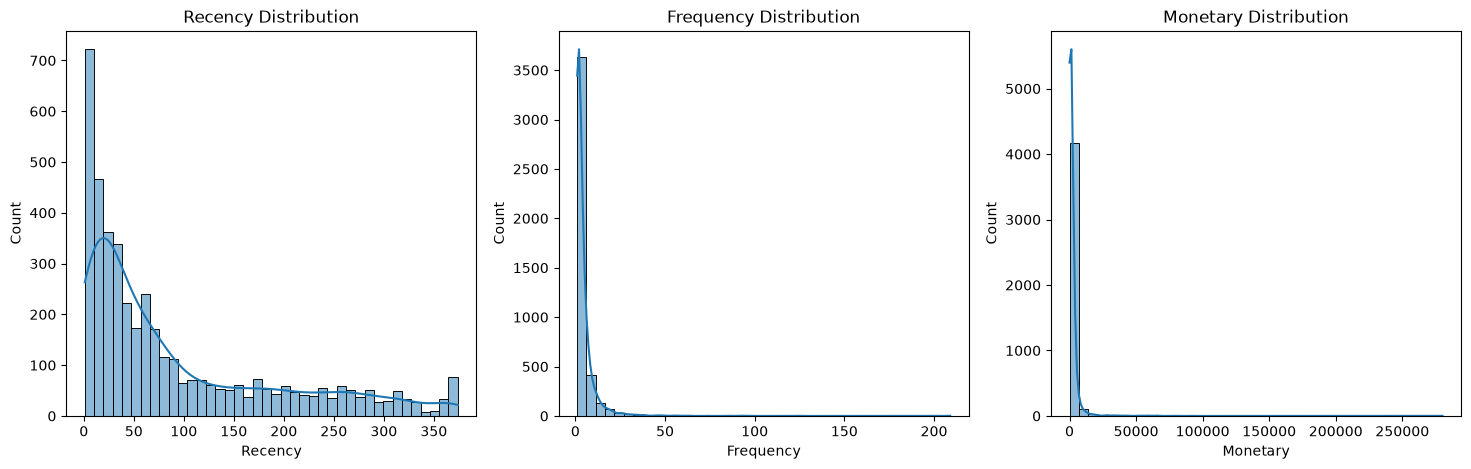

In [19]:
# 5️ RFM Distributions
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

# Plot distributions

fig, axes = plt.subplots(1, 3, figsize=(18,5))

sns.histplot(rfm['Recency'], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Recency Distribution")

sns.histplot(rfm['Frequency'], bins=40, kde=True, ax=axes[1])
axes[1].set_title("Frequency Distribution")

sns.histplot(rfm['Monetary'], bins=40, kde=True, ax=axes[2])
axes[2].set_title("Monetary Distribution")

plt.show()


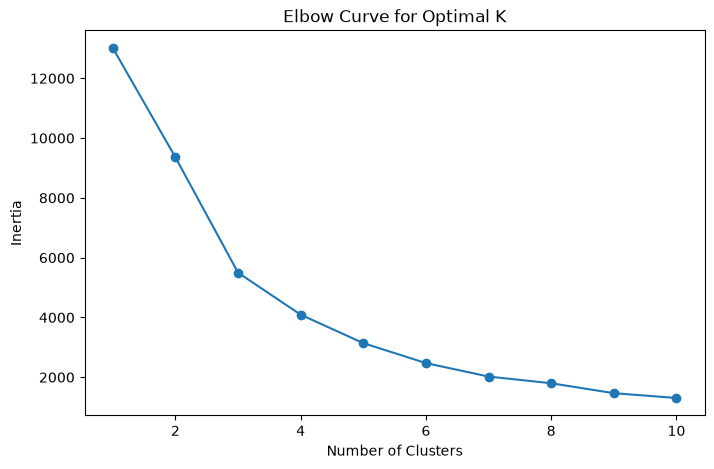

In [20]:
# Elbow Curve for K-Means Cluster Selection
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

#Elbow plot:
inertia = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(K, inertia, marker='o')
plt.title("Elbow Curve for Optimal K")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()


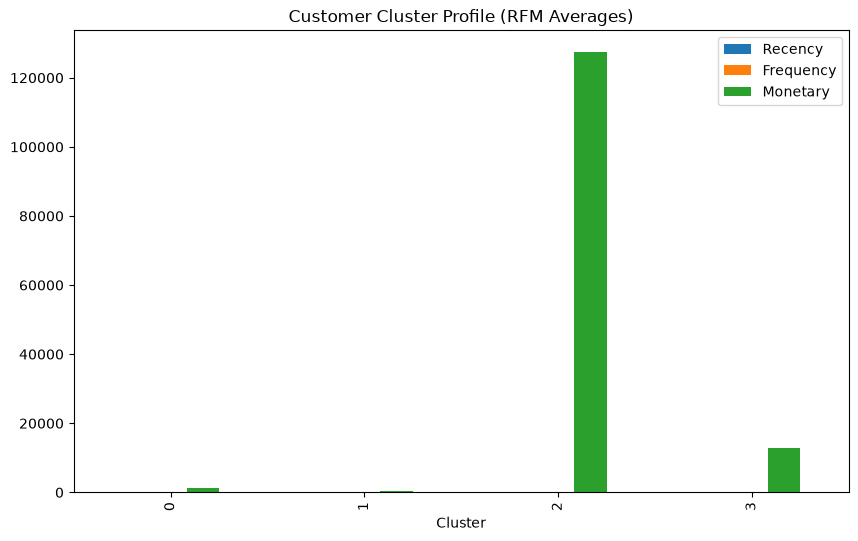

In [21]:
#Customer Cluster Profiles

#ssume K=4 (after elbow test): Cluster 0 — High-value customers,Cluster 1 — Regular customers,Cluster 2 — At-risk customers,Cluster 3 — Occasional or low-value customers

kmeans = KMeans(n_clusters=4, random_state=42)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

#Cluster summary

cluster_profile = rfm.groupby('Cluster').mean()
cluster_profile

#Visualize

cluster_profile.plot(kind='bar', figsize=(10,6))
plt.title("Customer Cluster Profile (RFM Averages)")
plt.show()


In [22]:
#Clustering Methodology
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,     # Recency
    'InvoiceNo': 'nunique',                                     # Frequency
    'TotalPrice': 'sum'                                         # Monetary
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']
    

In [23]:
#Standardize the RFM Values
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()         
rfm_scaled = scaler.fit_transform(rfm)


In [24]:
#Determine Best Number of Clusters

from sklearn.cluster import KMeans

inertia = []
K = range(1,11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

kmeans = KMeans(n_clusters=4, random_state=42)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)


In [25]:
rfm.groupby('Cluster').mean()

def label_cluster(row):
    r, f, m = row['Recency'], row['Frequency'], row['Monetary']

    if (r < rfm['Recency'].median()) and (f > rfm['Frequency'].median()) and (m > rfm['Monetary'].median()):
        return "High-Value"

    if (f >= rfm['Frequency'].median()) and (m >= rfm['Monetary'].median()):
        return "Regular"

    if (f < rfm['Frequency'].median()) and (m < rfm['Monetary'].median()) and (r > rfm['Recency'].median()):
        return "Occasional"

    return "At-Risk"

rfm['Segment'] = rfm.apply(label_cluster, axis=1)



In [26]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(rfm_scaled)


,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](4, 3)","[

In [27]:
import joblib

joblib.dump(kmeans, 'rfm_kmeans_model.pkl')
joblib.dump(scaler, 'rfm_scaler.pkl')


['rfm_scaler.pkl']

In [28]:
import joblib
sim = joblib.load("similarity_df.pkl")

print("Index sample:", list(sim.index[:5]))
print("Column sample:", list(sim.columns[:5]))


Index sample: ['10 COLOUR SPACEBOY PEN', '12 COLOURED PARTY BALLOONS', '12 DAISY PEGS IN WOOD BOX', '12 EGG HOUSE PAINTED WOOD', '12 HANGING EGGS HAND PAINTED']
Column sample: ['10 COLOUR SPACEBOY PEN', '12 COLOURED PARTY BALLOONS', '12 DAISY PEGS IN WOOD BOX', '12 EGG HOUSE PAINTED WOOD', '12 HANGING EGGS HAND PAINTED']
